In [1]:
import pandas as pd
import numpy as np

In [2]:
df_full = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [3]:
df_full

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2005,USA,Gasoline,All-wheel drive,4,2470,6,271.0,4690,18.9,27.4
9996,1993,Asia,Gasoline,All-wheel drive,2,2300,6,244.0,4370,19.0,30.0
9997,2014,USA,Gasoline,All-wheel drive,3,2480,6,267.0,4590,18.4,28.1
9998,2004,USA,Hybrid,Rear-wheel drive,5,2180,6,270.0,4450,20.9,32.2


In [4]:
## Select colums
df= df_full[['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year', 'fuel_efficiency_mpg']]

In [5]:
## Finding missing values
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [6]:
## plotting
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

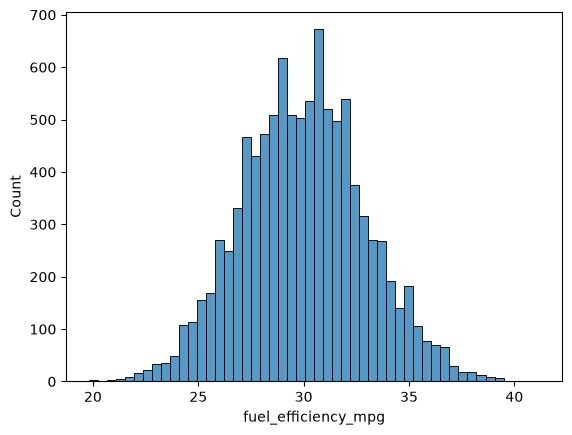

In [7]:
sns.histplot(df.fuel_efficiency_mpg, bins=50)

In [8]:
## Median of horsepower
df['horsepower'].median()

np.float64(254.0)

In [9]:
# Preparing and splitting dataset
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train+n_val:]]

In [10]:
df_train.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
6252,1900,239.0,3790,2015,32.5
4684,2000,224.0,4380,1992,29.1
1731,2330,286.0,4090,2022,34.1
4742,2300,NaN,4150,1997,30.6
4521,2340,269.0,4400,2001,30.7


In [11]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [12]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

In [13]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [14]:
## define functions
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [15]:
## Question 3
## missing values
### a. filling with 0

X_train = df_train.fillna(0).values

w0, w = train_linear_regression(X_train, y_train)

y_pred = w0 + X_train.dot(w)

In [16]:
w0

np.float64(-153.88496188223104)

In [17]:
w

array([-1.51505520e-03, -4.74024794e-06, -3.95418397e-03,  1.02146785e-01])

<Axes: ylabel='Count'>

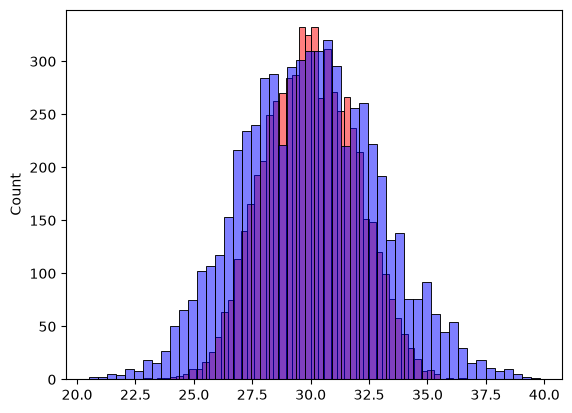

In [18]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [19]:
### b.  filling with the mean
mean = df_train['horsepower'].mean() # calcualting mean
X_train = df_train.fillna(value= mean)
X_train.isnull().sum() # checking

engine_displacement    0
horsepower             0
vehicle_weight         0
model_year             0
dtype: int64

In [20]:
w0, w = train_linear_regression(X_train, y_train)

y_pred = w0 + X_train.dot(w)

In [21]:
print(w0)
print(w)

-153.29645639182718
[-0.00102386 -0.00648622 -0.00388828  0.10197897]


<Axes: ylabel='Count'>

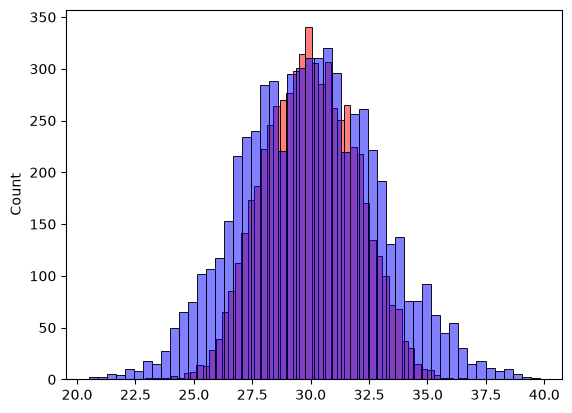

In [22]:
sns.histplot(y_pred, color='red', alpha=0.5, bins=50)
sns.histplot(y_train, color='blue', alpha=0.5, bins=50)

In [23]:
## Model validation
## rmse
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [24]:
### filling with 0
def prepare_X0(df):
    df_num = df.fillna(0)
    X = df_num.values
    return X

In [25]:
X_train = prepare_X0(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_X0(df_val)
y_pred = w0 + X_val.dot(w)
rmse0 = rmse(y_val, y_pred)
round(rmse0, 3)

np.float64(2.205)

In [26]:
### filling with mean
def prepare_Xmean(df):
    mean = df['horsepower'].mean()
    df_num = df.fillna(value=mean)
    X = df_num.values
    return X

In [27]:
X_train = prepare_Xmean(df_train)
w0, w = train_linear_regression(X_train, y_train)

X_val = prepare_Xmean(df_val)
y_pred = w0 + X_val.dot(w)
rmse_mean = rmse(y_val, y_pred)
round(rmse_mean, 3)

np.float64(2.202)

In [28]:
## Question 4
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [29]:
 for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    X_train = prepare_X0(df_train)
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)

    X_val = prepare_X0(df_val)
    y_pred = w0 + X_val.dot(w)

    score = rmse(y_val, y_pred)
    rmse_round = round(score, 4)
    print(r, w0, rmse_round)

0 -153.88496188223104 2.2053
0.01 -148.3092124404723 2.2058
0.1 -111.83871039307081 2.2241
1 -32.331865964969374 2.3492
5 -7.772852209978469 2.4094
10 -3.987116416019025 2.4195
100 -0.4082196488463344 2.4292


In [31]:
## Question 5
results = []

for seed in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]:
    # Preparing and splitting dataset
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test
    
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)
    
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    df_train = df_train.reset_index(drop=True)
    df_val = df_val.reset_index(drop=True)
    df_test = df_test.reset_index(drop=True)
    
    # Get target values
    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values
    y_test = df_test.fuel_efficiency_mpg.values
    
    # Remove target from features
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    # Fill missing values with 0
    X_train = prepare_X0(df_train)

    # Train model
    w0, w = train_linear_regression(X_train, y_train)

    # Evaluate model
    X_val = prepare_X0(df_val)
    y_pred = w0 + X_val.dot(w)

    score = rmse(y_val, y_pred)

    results.append(score)

    print(seed, w0, score)


0 -150.42885945053604 2.2392041430461465
1 -151.61231559524666 2.2021128210838907
2 -152.84068112584038 2.163419778753095
3 -152.33298096679223 2.2043588768539144
4 -158.88856816457883 2.2018800943312926
5 -151.8573533887713 2.2457851509084974
6 -154.3717913727048 2.269721207952404
7 -155.0183525899584 2.190794599933433
8 -150.4381740048234 2.2166112016864443
9 -154.36007488958072 2.207036592817851


In [33]:
std = np.std(results)
round(std,3)

np.float64(0.029)

In [34]:
## Question 6
# Preparing and splitting dataset
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

# Get target values
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

# Remove target from features
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

df_full_train = pd.concat([df_train, df_val])
df_full_train = df_full_train.reset_index(drop=True)
X_full_train = prepare_X0(df_full_train)
y_full_train = np.concatenate([y_train, y_val])
w0, w = train_linear_regression_reg(X_full_train, y_full_train, r=0.001)

X_test = prepare_X0(df_test)
y_pred = w0 + X_test.dot(w)
score = rmse(y_test, y_pred)
score

np.float64(2.2358277471917636)